In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
fake_df=pd.read_csv("/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/Fake.csv")
real_df=pd.read_csv("/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/True.csv")
print(fake_df.shape)
print(real_df.shape)

(23481, 4)
(21417, 4)


In [3]:
fake_df.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [4]:
fake_df['label']=0
real_df['label']=1

In [5]:
df=pd.concat([fake_df,real_df],ignore_index=True)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df.shape)
print(df['label'].value_counts())

(44898, 5)
label
0    23481
1    21417
Name: count, dtype: int64


In [6]:
df.isna().sum()

title      0
text       0
subject    0
date       0
label      0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(209)

In [8]:
df=df.drop_duplicates()

In [9]:
df.head()

,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 44689 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44689 non-null  object
 1   text     44689 non-null  object
 2   subject  44689 non-null  object
 3   date     44689 non-null  object
 4   label    44689 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 2.0+ MB


In [11]:
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True) * 100)

label
0    23478
1    21211
Name: count, dtype: int64
label
0    52.536418
1    47.463582
Name: proportion, dtype: float64


In [12]:
df=df.drop(columns=["date","subject"])

In [13]:
df["content"]=df['title']+' '+df["text"]

In [14]:
df = df[['content', 'label']]


In [15]:
df.shape

(44689, 2)

In [16]:
df.head()

,content,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,0
1,Trump drops Steve Bannon from National Securit...,1
2,Puerto Rico expects U.S. to lift Jones Act shi...,1
3,OOPS: Trump Just Accidentally Confirmed He Le...,0
4,Donald Trump heads for Scotland to reopen a go...,1


In [17]:
df["content"]=df["content"].apply(lambda x:x.lower())

In [18]:
import re

def clean_txt(txt):
    txt = re.sub(r"[^a-z\s]", " ", txt)
    return re.sub(r"\s+", " ", txt).strip()

df["content"] = df["content"].apply(clean_txt)

In [19]:
print(type(df['content']))
print(type(df['content'].iloc[0]))
print(df['content'].head())

<class 'pandas.core.series.Series'>
<class 'str'>
0    ben stein calls out th circuit court committed...
1    trump drops steve bannon from national securit...
2    puerto rico expects u s to lift jones act ship...
3    oops trump just accidentally confirmed he leak...
4    donald trump heads for scotland to reopen a go...
Name: content, dtype: object


In [20]:
def remove_numbers(txt):
    new_content=[]
    for i in txt:
        if not i.isdigit():
            new_content+=i
    return "".join(new_content)

df["content"]=df["content"].apply(remove_numbers)

In [21]:
df.head()

,content,label
0,ben stein calls out th circuit court committed...,0
1,trump drops steve bannon from national securit...,1
2,puerto rico expects u s to lift jones act ship...,1
3,oops trump just accidentally confirmed he leak...,0
4,donald trump heads for scotland to reopen a go...,1


In [23]:
print(df["content"].str.contains(r"\(Reuters\)", regex=True).groupby(df["label"]).sum())

df["content"] = df["content"].str.replace(r"^[^()]{0,100}\(Reuters\)\s*[-–]?\s*", "", regex=True)

print(df["content"].str.contains(r"\(Reuters\)", regex=True).groupby(df["label"]).sum())

label
0    0
1    0
Name: content, dtype: int64
label
0    0
1    0
Name: content, dtype: int64


In [36]:
from nltk.corpus import stopwords
import nltk
from nltk.tokenize import word_tokenize
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
stop_words=set(stopwords.words("english"))
stop_words = stop_words - {"not", "no", "nor", "never"}
stop_words.add("reuters")
artifact_words = {
    "monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday",
    "jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec",
    "washington",
    "via", "video", "image", "read", "watch", "featured", "wire", "com",
}
stop_words |= artifact_words
def remove_stopwords(txt):
    words=word_tokenize(txt)
    new=[]
    for word in words:
        if word not in stop_words:
            new.append(word)
    new_content=" ".join(new)
    return(new_content)
df["content"]=df["content"].apply(remove_stopwords)

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [37]:
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
lemmatizer=WordNetLemmatizer()
def lemmatze_word(txt):
    words=word_tokenize(txt)
    new_words=[]
    for word in words:
        lemma=lemmatizer.lemmatize(word)
        new_words.append(lemma)
    return" ".join(new_words)
        

[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [38]:
df["content"]=df["content"].apply(lemmatze_word)

In [39]:
print(df['content'].iloc[0])
print(df['content'].str.len().describe())
print(df.isnull().sum())

ben stein call th circuit court committed coup tat constitution st century say ben stein reputable professor pepperdine university also hollywood fame appearing tv show film ferris bueller day made provocative statement judge jeanine pirro show recently discussing halt imposed president trump executive order travel stein referred judgement th circuit court state coup tat executive branch constitution stein went call judge seattle political puppet judiciary political pawn interview complete statement note stark contrast rhetoric leftist medium pundit neglect note no court ever blocked presidential order immigration past discus legal efficacy halt actual text executive order trump news st century trump filessupport work subscribing becoming member tv
count    44689.000000
mean      1734.132382
std       1503.607152
min         20.000000
25%        895.000000
50%       1522.000000
75%       2156.000000
max      37975.000000
Name: content, dtype: float64
content    0
label      0
dtype: in

In [40]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(df["content"],df["label"],test_size=0.2,random_state=42)

In [41]:


from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer=TfidfVectorizer()
x_train_tf=vectorizer.fit_transform(x_train)
x_test_tf=vectorizer.transform(x_test)
print(vectorizer.get_feature_names_out())

['aa' 'aaa' 'aaaaaaaand' ... 'zzzzaaaacccchhh' 'zzzzzzzz' 'zzzzzzzzzzzzz']


In [42]:
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))
print("Training shape:", x_train_tf.shape)
print("Testing shape:", x_test_tf.shape)

Vocabulary size: 98302
Training shape: (35751, 98302)
Testing shape: (8938, 98302)


In [43]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(x_train_tf,y_train)
y_predict=model.predict(x_test_tf)
probabilities = model.predict_proba(x_test_tf)


In [44]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,f1_score
print("accuracy_score:",accuracy_score(y_test,y_predict))
print("confusion_matrix",confusion_matrix(y_test,y_predict))
print("classification_report",classification_report(y_test,y_predict))
print("F1 Score:", f1_score(y_test, y_predict))

accuracy_score: 0.9773998657417767
confusion_matrix [[4533  119]
 [  83 4203]]
classification_report               precision    recall  f1-score   support

           0       0.98      0.97      0.98      4652
           1       0.97      0.98      0.98      4286

    accuracy                           0.98      8938
   macro avg       0.98      0.98      0.98      8938
weighted avg       0.98      0.98      0.98      8938

F1 Score: 0.9765334572490706


In [45]:

from sklearn.svm import LinearSVC

svm = LinearSVC()
svm.fit(x_train_tf, y_train)
svm_pred = svm.predict(x_test_tf)

print("SVM accuracy:", accuracy_score(y_test, svm_pred))
print("SVM F1:", f1_score(y_test, svm_pred))

SVM accuracy: 0.9861266502573283
SVM F1: 0.9855847477330854


In [46]:
feature_names = vectorizer.get_feature_names_out()
coefs = model.coef_[0]
print("REAL:", [feature_names[i] for i in np.argsort(coefs)[-15:][::-1]])
print("FAKE:", [feature_names[i] for i in np.argsort(coefs)[:15]])

REAL: ['said', 'presidential', 'minister', 'told', 'democratic', 'representative', 'spokesman', 'statement', 'comment', 'republican', 'london', 'rival', 'house', 'senate', 'agency']
FAKE: ['gop', 'hillary', 'mr', 'even', 'getty', 'pic', 'america', 'like', 'http', 'breaking', 'obama', 'american', 'sen', 'rep', 'isi']


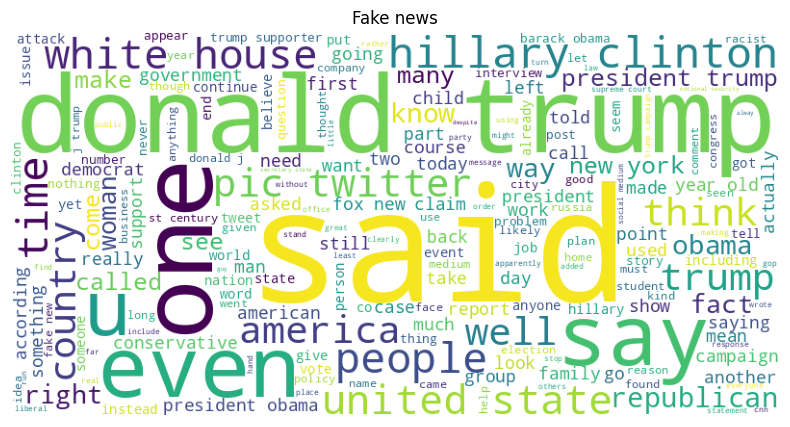

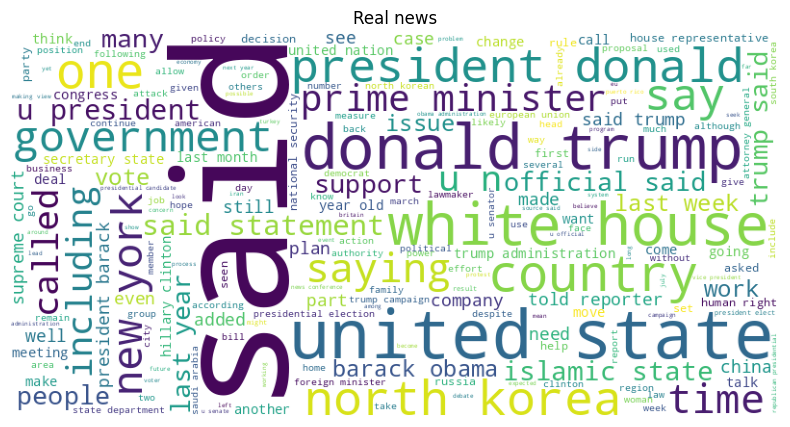

In [47]:
from wordcloud import WordCloud

for label, name in [(0, "Fake"), (1, "Real")]:
    text = " ".join(df[df["label"] == label]["content"])
    wc = WordCloud(width=800, height=400, background_color="white").generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc)
    plt.axis("off")
    plt.title(f"{name} news")
    plt.show()

In [48]:
import joblib

joblib.dump(
    {"vectorizer": vectorizer, "lr": model, "svm": svm, "stop_words": stop_words},
    "fake_news_model.joblib",
)

['fake_news_model.joblib']